# 05. Обратная задача: генерируем датасет под процесс TO BE

**Дисциплина:** «Управление и аналитика данных на предприятии» · СПбПУ, ИПМЭиТ · Лекция 7

**Профиль:** все профили (мост ЛР1 → ЛР2); пример — мониторинг факельного ствола НПЗ

**Бизнес-вопрос:** В модели TO BE (ЛР1) решение принимается «на основе данных», но открытого датасета нет. Какие переменные нужны, чтобы такое решение было возможно, и сработает ли на них наш алгоритм классификации?

**Данные:** генерируется в этом ноутбуке (`flare_monitoring_synthetic.csv`), сценарий — из материала курса «Примеры проблемных областей в промышленности» (инклинометры на этажерке факельного ствола + газоанализаторы).

---
Ноутбук построен по единому сценарию из 10 шагов (см. лекцию 7): *вопрос → загрузка → паспорт данных → очистка → разведка → связи и тренды → постановка ML-задачи → train/test → модель и базовая линия → качество и вывод для бизнеса*. Запуск: «Среда выполнения → Выполнить всё». Данные загружаются по постоянной ссылке с GitHub — ничего загружать вручную не нужно.

## Шаг 1. От BPMN к таблице: какие данные нужны процессу TO BE?

**AS IS:** осмотр факельного ствола — по графику раз в квартал; аварийные крены обнаруживаются поздно.
**TO BE:** датчики → сервер мониторинга → **модель оценивает риск** → при высоком риске автоматически создаётся заявка на внеплановый осмотр.

| элемент BPMN (TO BE) | вопрос к данным | переменная |
|---|---|---|
| событие-триггер «пришли показания» | что измеряем? | `tilt_x_deg`, `tilt_y_deg`, `wind_ms`, `air_temp_c`, `ch4_ppm`, `so2_ppm`, `flare_load_pct` |
| контекст объекта | что влияет на риск? | `days_since_inspection` |
| шлюз «риск высокий?» | что предсказываем? | **`inspection_needed`** (0/1) — целевая переменная |
| результат: заявка в ТОиР | как оцениваем качество? | recall (не пропустить), precision (не гонять бригаду зря) |

**Правило:** каждая переменная должна быть (1) измеримой на практике, (2) доступной *до* решения (без утечки ответа), (3) связанной с решением гипотезой.

In [1]:
# Шаг 0. Подключаем библиотеки (как в базовом примере)
import numpy as np                 # вычисления
import pandas as pd                # таблицы
import seaborn as sns              # графики
import matplotlib.pyplot as plt    # графики

sns.set_theme(style="whitegrid", palette=["#37B34A", "#244128", "#7248A0", "#F39768", "#DA4927"])
pd.set_option("display.max_columns", 30)

## Шаг 2. Генератор: закладываем «скрытые законы» + шум + реальные дефекты данных

Мы **знаем** истинные зависимости — значит, можем проверить, найдёт ли их модель. Специально добавлены пропуски и сбои датчиков, чтобы отработать очистку.

In [2]:
rng = np.random.default_rng(2026)
N = 3000

data = pd.DataFrame({
    "tilt_x_deg": rng.normal(0, 0.25, N),
    "tilt_y_deg": rng.normal(0, 0.25, N),
    "wind_ms": rng.gamma(2.2, 2.5, N).round(1),
    "air_temp_c": rng.normal(2, 12, N).round(1),
    "ch4_ppm": rng.lognormal(1.2, 0.6, N).round(2),
    "so2_ppm": rng.lognormal(-0.5, 0.7, N).round(3),
    "flare_load_pct": rng.uniform(5, 100, N).round(1),
    "days_since_inspection": rng.integers(0, 120, N),
})
tilt = np.hypot(data["tilt_x_deg"], data["tilt_y_deg"])      # полный угол крена

# «Скрытый закон» риска (логит). Знаки и сила влияния заданы осознанно:
z = (-4.2 + 6.0 * tilt + 0.18 * data["wind_ms"] + 0.015 * data["days_since_inspection"]
     + 0.25 * np.log(data["ch4_ppm"]) + 0.012 * data["flare_load_pct"]
     - 0.01 * data["air_temp_c"] + rng.normal(0, 0.6, N))
data["inspection_needed"] = (rng.uniform(size=N) < 1 / (1 + np.exp(-z))).astype(int)

# Дефекты реальной телеметрии: 2% пропусков и 0,5% «зависаний» датчика (значение 99)
for col in ["wind_ms", "ch4_ppm"]:
    data.loc[rng.choice(N, int(0.02 * N), replace=False), col] = np.nan
data.loc[rng.choice(N, int(0.005 * N), replace=False), "tilt_x_deg"] = 99.0

data.to_csv("flare_monitoring_synthetic.csv", index=False)
print(data.shape, "| доля «нужен осмотр»:", round(data["inspection_needed"].mean(), 3))
data.head()

(3000, 9) | доля «нужен осмотр»: 0.583


,tilt_x_deg,tilt_y_deg,wind_ms,air_temp_c,ch4_ppm,so2_ppm,flare_load_pct,days_since_inspection,inspection_needed
0,-0.198281,-0.113001,6.0,3.3,3.56,0.299,47.9,89,1
1,0.060143,-0.088274,3.2,-4.2,3.14,0.152,17.5,13,0
2,-0.474082,-0.235584,2.9,-2.2,21.36,0.867,31.2,5,0
3,0.348943,0.002755,4.3,2.1,2.22,0.563,47.6,119,1
4,0.159574,0.297611,8.0,15.3,2.21,0.108,57.0,103,1


> Файл `flare_monitoring_synthetic.csv` можно скачать (панель «Файлы» слева) и открыть в **Orange** или Excel — тот же датасет, другой инструмент.

## Шаги 3–4. Паспорт и очистка (как с «настоящими» данными)

In [3]:
df = pd.read_csv("flare_monitoring_synthetic.csv")
print(df.isna().sum()[lambda s: s > 0])
print("Сбой датчика (|крен| > 10°):", (df["tilt_x_deg"].abs() > 10).sum())
df = df[df["tilt_x_deg"].abs() <= 10].copy()                          # сбой датчика — удаляем строку
df[["wind_ms", "ch4_ppm"]] = df[["wind_ms", "ch4_ppm"]].fillna(df[["wind_ms", "ch4_ppm"]].median())
df["tilt_total"] = np.hypot(df["tilt_x_deg"], df["tilt_y_deg"])       # инженерный признак
df.shape

wind_ms    60
ch4_ppm    60
dtype: int64
Сбой датчика (|крен| > 10°): 15


(2985, 10)

## Шаги 5–6. Разведка

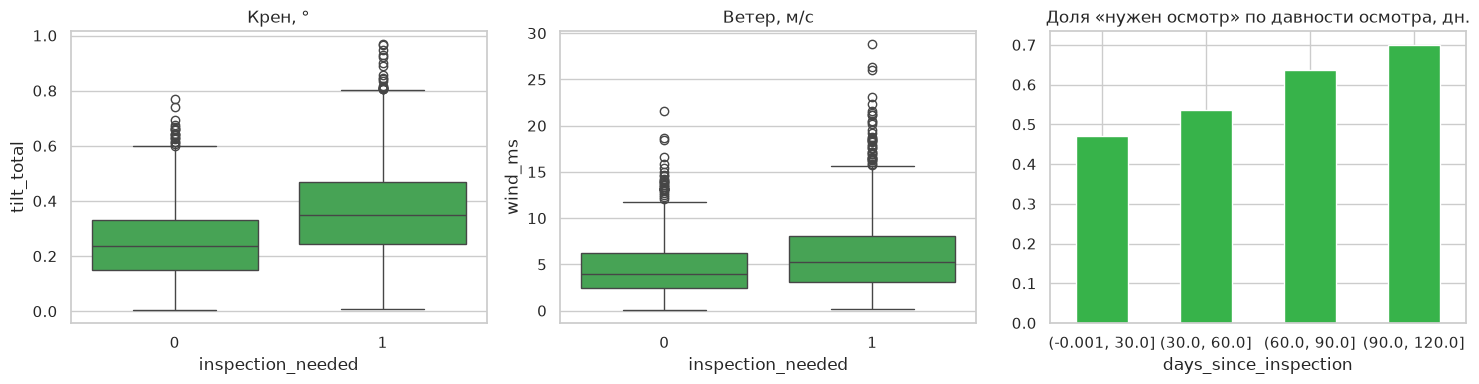

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="inspection_needed", y="tilt_total", ax=ax[0]); ax[0].set_title("Крен, °")
sns.boxplot(data=df, x="inspection_needed", y="wind_ms", ax=ax[1]); ax[1].set_title("Ветер, м/с")
df.groupby(pd.cut(df["days_since_inspection"], [0, 30, 60, 90, 120], include_lowest=True), observed=True)["inspection_needed"].mean().plot.bar(ax=ax[2], color="#37B34A")
ax[2].set_title("Доля «нужен осмотр» по давности осмотра, дн."); ax[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## Шаги 7–10. Модель, качество — и проверка: нашла ли модель «скрытый закон»?

Базовая линия                accuracy=0.582  precision=0.582  recall=1.000  f1=0.736
Логистическая регрессия      accuracy=0.751  precision=0.759  recall=0.839  f1=0.797  ROC-AUC=0.789


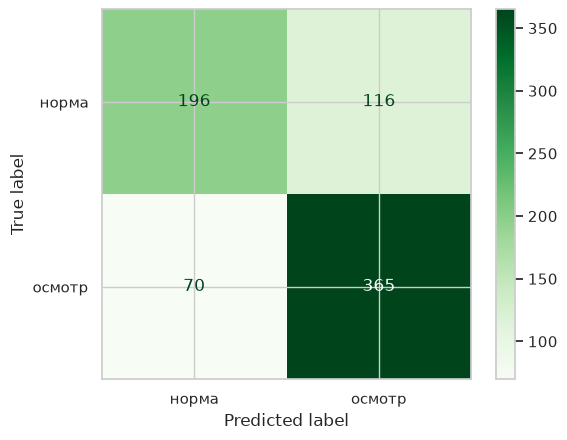

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

def quality(y_true, y_pred, y_proba=None, name="модель"):
    """Печатает ключевые метрики качества классификатора одной строкой."""
    line = (f"{name:<28} accuracy={accuracy_score(y_true, y_pred):.3f}  "
            f"precision={precision_score(y_true, y_pred, zero_division=0):.3f}  "
            f"recall={recall_score(y_true, y_pred):.3f}  f1={f1_score(y_true, y_pred):.3f}")
    if y_proba is not None:
        line += f"  ROC-AUC={roc_auc_score(y_true, y_proba):.3f}"
    print(line)

features = ["tilt_total", "wind_ms", "air_temp_c", "ch4_ppm", "so2_ppm", "flare_load_pct", "days_since_inspection"]
X, y = df[features], df["inspection_needed"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
quality(y_te, DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr).predict(X_te), name="Базовая линия")
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)
pred, proba = model.predict(X_te), model.predict_proba(X_te)[:, 1]
quality(y_te, pred, proba, name="Логистическая регрессия")
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["норма", "осмотр"]).plot(cmap="Greens"); plt.show()

In [6]:
truth = pd.Series({"tilt_total": "+ сильно", "wind_ms": "+", "air_temp_c": "− слабо", "ch4_ppm": "+ (лог)",
                   "so2_ppm": "0 (не влияет)", "flare_load_pct": "+", "days_since_inspection": "+"})
pd.DataFrame({"заложено в генератор": truth,
              "вес модели (станд.)": pd.Series(model[-1].coef_[0], index=features).round(2)})

,заложено в генератор,вес модели (станд.)
tilt_total,+ сильно,0.92
wind_ms,+,0.45
air_temp_c,− слабо,-0.12
ch4_ppm,+ (лог),0.16
so2_ppm,0 (не влияет),0.03
flare_load_pct,+,0.34
days_since_inspection,+,0.41


## Выводы

1. Модель **восстановила знаки и порядок силы** заложенных зависимостей: крен — главный фактор, за ним ветер, давность осмотра и нагрузка факела; SO₂ — почти ноль (мы его и не закладывали). Значит, *набор переменных достаточен* для решения в шлюзе TO BE.
2. Синтетика проверяет **логику процесса и алгоритма**, но **не доказывает** реальный эффект: в реальности зависимости неизвестны. Следующий шаг — запрос реальных данных у владельца процесса (SCADA/АСУ ТП) по той же схеме столбцов.
3. Схема столбцов — это **техническое задание на сбор данных**: её можно приложить к модели TO BE в ЛР1 и к обоснованию ЛР2.

---
### Шаблон запроса к ИИ-ассистенту (GigaChat / YandexGPT / DeepSeek и др.) для своей темы

```
Роль: аналитик данных промышленного предприятия.
Контекст: процесс TO BE «<название>» (BPMN из ЛР1). Решение в шлюзе «<вопрос>» должно приниматься по данным.
Задача: предложи 6–10 измеримых переменных (название_латиницей, единицы, диапазон, источник данных в компании),
целевую бинарную переменную и правдоподобные зависимости (знак и сила влияния).
Затем напиши код Python (numpy, pandas) для генерации CSV на 2000–5000 строк:
логистическая зависимость цели от признаков + шум, 1–3% пропусков, 0,5% выбросов-сбоев.
Не используй переменные, известные только после события (утечка ответа).
```
**Обязательно** проверьте предложенные ИИ зависимости на здравый смысл и укажите в отчёте, что данные синтетические.